In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import h5py

In [2]:
file_path = "/home/jake/Documents/AI_Clinician/dynamic_deephit_results/mimic_iv/five_splits/split_0/final_model/mimic_iv_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260215_153106_114049_job451246"
predictions_file = 'test_set_predictions.h5'

# get the keys in the h5 file
with h5py.File(os.path.join(file_path, predictions_file), 'r') as f:
    print("Keys in the h5 file:", list(f.keys()))

Keys in the h5 file: ['entropy', 'event', 'feature_dim', 'feature_names', 'health_score', 'index_ptr', 'model_outputs', 'physiological_feature_ind', 'physiological_feature_type', 'predictions', 'stay_ids', 'time_to_event', 'time_to_event_raw', 'trajectories']


In [3]:
# open the predictions and get the stay_ids
with h5py.File(os.path.join(file_path, predictions_file), 'r') as f:
    stay_ids = f['stay_ids'][:]
    print("Stay IDs:", stay_ids)

Stay IDs: [30001336 30002548 30004798 ... 39996123 39998138 39998622]


In [4]:
len(stay_ids)

15157

In [37]:
file_path = "/home/jake/Documents/AI_Clinician/mimic_iv_3.1_data/combined_data/hourly_all_patients/tuning_set"

file = "tuning_all_windows_index_table_transformer_72.parquet"

df = pd.read_parquet(os.path.join(file_path, file))
print(df)

        stay_id  window_idx  sample_end_idx  time_to_event  event_raw
0      30000484           0              63              1          0
1      30002498           1              27              1          0
2      30003130           2              25              1          0
3      30003306           3              50              1          0
4      30003598           4              71             47          0
...         ...         ...             ...            ...        ...
22797  39997159       23860              57              1          0
22798  39997370       23861              71             25          0
22799  39997370       23862              23              1          0
22800  39997955       23863              71             44          0
22801  39997955       23864              42              1          0

[22802 rows x 5 columns]


In [38]:
file = "tuning_index_table_transformer_72.parquet"
df = pd.read_parquet(os.path.join(file_path, file))
print(df)

        stay_id                               shard_file  window_idx  \
0      30000484  tuning0_shard_normalized_transformer.h5           0   
1      30002498  tuning0_shard_normalized_transformer.h5           1   
2      30003130  tuning0_shard_normalized_transformer.h5           2   
3      30003306  tuning0_shard_normalized_transformer.h5           3   
4      30003598  tuning0_shard_normalized_transformer.h5           4   
...         ...                                      ...         ...   
11379  39993683  tuning0_shard_normalized_transformer.h5       23852   
11380  39996867  tuning0_shard_normalized_transformer.h5       23853   
11381  39997159  tuning0_shard_normalized_transformer.h5       23859   
11382  39997370  tuning0_shard_normalized_transformer.h5       23861   
11383  39997955  tuning0_shard_normalized_transformer.h5       23863   

       window_end_idx  length  event  
0                  63      64      0  
1                  27      28      0  
2                 

In [3]:
file_path = "/home/jake/Documents/AI_Clinician/mimic_iv_3.1_data/combined_data/hourly_all_patients/training_set"

shard_file_name = "train0_shard.h5"

shard_file = os.path.join(file_path, shard_file_name)

with h5py.File(shard_file, 'r') as f:      
    # convert feature_names from bytes to strings
    feature_names = [f['feature_names'][i].decode('utf-8') for i in range(len(f['feature_names']))]                
    stay_ids = f['stay_ids'][:]
    index_ptr = f['index_ptr'][:]
    trajectories = f['trajectories'][:] 

In [6]:
stay_ids.shape

(53116,)

In [7]:
index_ptr.shape

(53117,)

In [8]:
index_ptr

array([      0,     129,     243, ..., 6311530, 6311559, 6311655],
      dtype=int32)

In [4]:
trajectories.shape

(6311655, 83)

In [5]:
feature_names

['age',
 'death',
 'black',
 'other',
 'sex',
 'white',
 'ecmo_binary',
 'combined_hourly_iv',
 'weight',
 'impella_binary',
 'calcium_non_ionized',
 'chloride',
 'creatinine',
 'glucose',
 'hco3_serum',
 'hematocrit',
 'hemoglobin',
 'inr',
 'magnesium',
 'partial_thr_time',
 'platelet_count',
 'potassium_serum',
 'prothrombin_time',
 'sodium',
 'wbc',
 'cisatracurium_bolus',
 'cisatracurium_infusion',
 'dobutamine_infusion',
 'dopamine_infusion',
 'epinephrine_bolus',
 'epinephrine_infusion',
 'fentanyl_bolus',
 'fentanyl_infusion',
 'furosemide_bolus',
 'furosemide_infusion',
 'heparin_sodium_prophylaxis',
 'hydralazine_bolus',
 'hydromorphone_bolus',
 'hydromorphone_infusion',
 'ketamine_bolus',
 'ketamine_infusion',
 'labetalol_bolus',
 'labetalol_infusion',
 'milrinone_infusion',
 'nitroglycerin_infusion',
 'norepinephrine_infusion',
 'phenylephrine_infusion',
 'propofol_bolus',
 'propofol_infusion',
 'vasopressin_infusion',
 'vecuronium_bolus',
 'vecuronium_infusion',
 'vasoacti

In [9]:
trajectory_lengths = index_ptr[1:] - index_ptr[:-1]
trajectory_lengths

array([129, 114,  74, ...,  26,  29,  96], dtype=int32)

In [24]:
# remove any trajectories longer than 2 months (1440 hours)
valid_indices = np.where(trajectory_lengths <= 1440)[0]
stay_ids = stay_ids[valid_indices]
trajectory_lengths = trajectory_lengths[valid_indices]
trajectory_lengths

array([129, 114,  74, ...,  26,  29,  96], dtype=int32)

In [25]:
tte = []
for i, stay_id in enumerate(stay_ids):
    traj_length = trajectory_lengths[i]

    time_to_event = np.arange(traj_length)[::-1]

    tte.append(time_to_event)

tte = np.concatenate(tte)

In [33]:
# calculate percentiles for 8 bins 
time_bins = np.percentile(tte, [12.5 * i for i in range(1, 9)])
time_bins


array([  13.,   28.,   47.,   75.,  116.,  185.,  322., 1435.])

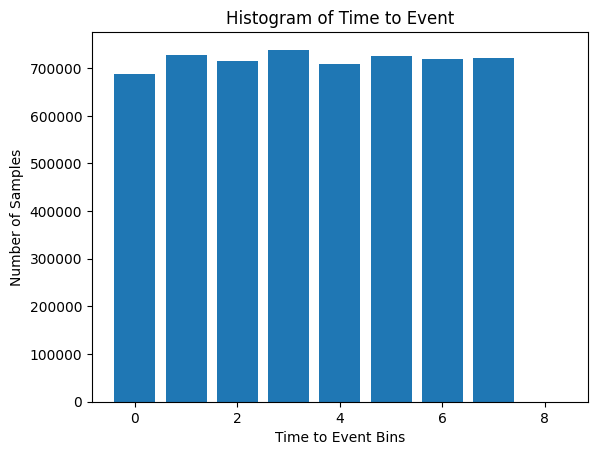

In [32]:
# calculate a histogram of time to event using the time bins
hist, bin_edges = np.histogram(tte, bins=[-1] + list(time_bins) + [tte.max()+1])

# plot histogram
plt.bar(range(len(hist)), hist)
plt.xlabel('Time to Event Bins')
plt.ylabel('Number of Samples')
plt.title('Histogram of Time to Event')
plt.show()


In [23]:
trajectory_lengths.max()

np.int32(52967)